

# Table of Contents

**Phase 1: Data Preparation and Metrics Definition**
- 1.1 Preprocessing and Data Cleaning
- 1.2 Definition of Key Metrics
- 1.3 Network Construction and Representation

**Phase 2: Outbreak Detection and Analysis**  
- 2.1 Community Exploration and Structure Analysis	
- 2.2 Outbreak Identification and Characterization

**Phase 3: Propagation and Diffusion Analysis**  
- 3.1 Cascade Tracing and Flow Dynamics
- 3.2 Immunity and Containment Effects

**Phase 4: Lifecycle and Evolution Study**  
- 4.1 Detection of Cycles and Key Events
- 4.2 Evolutionary Tracking Over Time

**Phase 5: Validation and Synthesis of Results**  
- 5.1 Cross-Validation and Robustness Checks
- 5.2 Final Interpretation and Conclusions


### **Install Requirements**

In [1]:
%pip install -r pip_requirements.txt

Note: you may need to restart the kernel to use updated packages.


### **Imports**

*Note that you need a 'Data' folder containing the 4 datasets defined in the README. This folder should be placed at the same level as src and tests directories.*

In [2]:
# Jupyter Notebook Utils
%matplotlib inline
%load_ext autoreload
%autoreload 2

# Python Libraries
import pandas as pd
import numpy as np
import matplotlib.dates as mdates
from datetime import date
import matplotlib.pyplot as plt
import seaborn as sns
import math
from scipy import stats
from statsmodels.stats import diagnostic
import statsmodels.api as sm
import statsmodels.formula.api as smf

# Own modules
from src import *

# Project pipeline




In [3]:
%reload_ext autoreload

---
# Phase 1: Data Preparation

## 1.1 Preprocessing & Cleaning


### Data Quality Checks, Unification & Standardization

We import and preprocess data through the following steps:

1. Import TSV files and expand PROPERTIES column into 86 features
2. Merge together both title and body datasets in a unified dataset, with `TYPE` to retain information of source.
3. Standardize subreddit names (lowercase, trim whitespace)
4. Convert timestamps to datetime and chronologically reorder the combined dataset (temporal integrity was altered by merging)
5. Format embeddings datasets (one subreddit per row, one column for each embedding dimension)
6. Check data quality (missing values, timestamp parsing)
7. Check for duplicates and document dataset overlap

The steps are performed using functions defined in `init_data.py`.

In [4]:
# Data quality and duplicates check
check_quality(interactions_df)
check_quality(embeddings_subreddits_df)
check_quality(embeddings_users_df)


=== QUALITY REPORT ===
Shape: (858488, 92)

Missing values:
 SOURCE_SUBREDDIT                          0
LIWC_COGMECH                              0
LIWC_PERCEPT                              0
LIWC_EXCL                                 0
LIWC_INCL                                 0
                                         ..
LIWC_PPRON                                0
LIWC_PRONOUN                              0
LIWC_FUNCT                                0
COMPOUND_SENTIMENT_CALCULATED_BY_VADER    0
TYPE                                      0
Length: 92, dtype: int64

Duplicate rows: 0

=== QUALITY REPORT ===
Shape: (51278, 301)

Missing values:
 SUBREDDIT    0
emb_206      0
emb_204      0
emb_203      0
emb_202      0
            ..
emb_99       0
emb_98       0
emb_97       0
emb_96       0
emb_299      0
Length: 301, dtype: int64

Duplicate rows: 0

=== QUALITY REPORT ===
Shape: (118381, 301)

Missing values:
 USER       0
emb_206    0
emb_204    0
emb_203    0
emb_202    0
          

In [5]:
# DataFrame after STEP 1 
interactions_df.head()

,SOURCE_SUBREDDIT,TARGET_SUBREDDIT,POST_ID,TIMESTAMP,LINK_SENTIMENT,NUMBER_OF_CHARACTERS,NUMBER_OF_CHARACTERS_WITHOUT_COUNTING_WHITE_SPACE,FRACTION_OF_ALPHABETICAL_CHARACTERS,FRACTION_OF_DIGITS,FRACTION_OF_UPPERCASE_CHARACTERS,...,LIWC_LEISURE,LIWC_HOME,LIWC_MONEY,LIWC_RELIG,LIWC_DEATH,LIWC_ASSENT,LIWC_DISSENT,LIWC_NONFLU,LIWC_FILLER,TYPE
0,agitation,changemyview,1u5cj7s,2013-12-31 16:20:20,1,102.0,91.0,0.843137,0.000000,0.088235,...,0.000000,0.0,0.0,0.0,0.0000,0.0,0.0,0.000000,0.000000,title
1,rddtgaming,rddtrust,1u4pzzs,2013-12-31 16:39:18,1,25.0,23.0,0.760000,0.000000,0.440000,...,0.000000,0.0,0.0,0.0,0.0000,0.0,0.0,0.000000,0.000000,title
2,leagueoflegends,teamredditteams,1u4nrps,2013-12-31 16:39:58,1,345.0,298.0,0.756522,0.017391,0.086957,...,0.034483,0.0,0.0,0.0,0.0000,0.0,0.0,0.000000,0.000000,body
3,examplesofevil,pics,1u5lhas,2013-12-31 16:40:29,1,96.0,83.0,0.833333,0.000000,0.062500,...,0.000000,0.0,0.0,0.0,0.0625,0.0,0.0,0.000000,0.000000,title
4,nfl,cfb,1u4sjvs,2013-12-31 17:37:55,1,1124.0,949.0,0.772242,0.001779,0.057829,...,0.020833,0.0,0.0,0.0,0.0000,0.0,0.0,0.020833,0.005208,body


## 1.2 Definition of Key Metrics



**Aggregation Levels:**
All metrics computed at multiple scopes:
- Subreddit level (aggregated over time windows)
- Subreddit-pair level (source → target relationships)
- Community cluster level (aggregated within detected communities)

### 1.2.1 Core Toxicity Metric

Our first fundamental preliminary step is to calculate a reliable and accurate metric of toxicity of each subreddit's post.

By toxicity, we refer to patterns of communication or behavior that create a hostile, disrespectful, or harmful environment for participants. This can include insults, harassment, hate speech, excessive negativity, or attempts to provoke conflict. Toxicity reduces constructive discussion, discourages participation, and can damage the overall health and cohesion of the community.

The majority of these characteristics are captured by some of the 86 properties that are already includeded in our dataset. Let's understand what they actually represent.

**Properties 1 to 18** capture surface-level linguistic and structures of the text. They measure the basic composition and readability of a message, including its length, complexity, and word or sentence structure. They include metrics such as character and word counts, fractions of different character types (letters, digits, punctuation, etc.), sentence length averages, and readability scores. Together, they provide a quantitative snapshot of how the text is written rather than what it expresses.

**Properties 19 to 21** represent sentiment analysis metrics, derived using the VADER (Valence Aware Dictionary and sEntiment Reasoner) model. They aim to measure the emotional polarity of the text. It includes the Positive Sentiment, Negative Sentiment and Compound Sentiment. These features reflect the emotional valence of the language used.

**Properties 22 to 86** are purely lexicon-based ratios, derived using a text analyis tool called Linguistic Inquiry and Word Count (LIWC). Each LIWC represent the proportion of words in a text that belong to a certain lexicon: LIWC_X = (nb words in lexicon X) / (total nb words). While useful to see the presence of a certain vocubulary in a post, they remain purely lexical and doesn't treat emotion or sentiment in any way.

<div style="border: 2px solid #ff0000ff; border-radius: 10px; padding: 10px; display: inline-block; width: 90%; box-sizing: border-box;">
<code>TOXICITY_SCORE</code>: continuous metric that measures the toxicity intensity in a subreddit post, using the 86 existing properties 
</div>

(Function also implemented in `compute_toxicity_score.py` in `utils` module.)

**Properties that are interesting for capturing toxicity**

| Dimension | Description | Example of properties to use |
|------------|--------------|------------------|
| **Emotional intensity** | Measures strength of negative emotion | `Neg_Vader`, `LIWC_Negemo`, `LIWC_Anger`, `LIWC_Anx`... |
| **Aggressive** | Captures hostile or taboo language | `LIWC_Swear`, `LIWC_Sexual`, `LIWC_Death`, `LIWC_Relig`... |
| **Targeting** | Focus on others (potential hostility toward people/groups) | `LIWC_You`, `LIWC_Humans`, `LIWC_Social`... |
| **Not cognitive** | Opposite of reasoned or analytical tone | `LIWC_Insight`, `LIWC_Cause`... |
| **Violent and short** | Style indicators of impulsive or aggressive speech | `Number of UPPERCASE words`, `Readability index`... 

However, above all these textual properties, we also consider true **negativity** of a post to be a **necessary** component for it to be toxic.

**The problem: none of the 86 properties provides a reliable measure of emotional negativity in a post.** 

While the VADER scores seemed promising (optimized for social media texts and posts), they mainly work like a LIWC score and calculate emotion of the **language** that was used (like an advanced lexical repertory of words that are conventionally considered negative or harmful on social platforms).

This cannot be considered an accurate measure of negativity in our context. For example, some shortfalls of lexical metrics include:

- Sarcasm, irony, and context
  - “Stupid guy” in a link targeting a funny video of a guy slipping 
  - “Stupid guy” in a link targeting a video of Trump’s speech  

- Cultural difference in language
  - Some communities are (by culture) founded on “offensive” language without being toxic.
  - For example, a *CallOfDuty* subreddit will frequently mention terms like “grenade” or “headshots.” These words are not toxic in that community, but could be considered so in other subreddits (ones not related to war or gaming).

**Good news: `LINK_SENTIMENT` solves this problem.**

`LINK_SENTIMENT` is derived using a supervised sentiment classifier trained on manually labeled Reddit data. When labeling, the authors have taken into account their human judgement of context, irony etc. in addition of a purely lexical analysis. So `LINK_SENTIMENT` is designed specifically for inter-subreddit interactions and is our most reliable (categorical) measure for pure negativity.

We want to explore what are the properties that play a determinant role in negativity. To do so, we compare the normalized property means between positive and negative links (normalized because some properties have different scales and centers). Look which are the most significantly different for positive VS negative links.

The threshold for significant difference was arbitrrary set to 0.25 to retain around 20 properties.

test lala


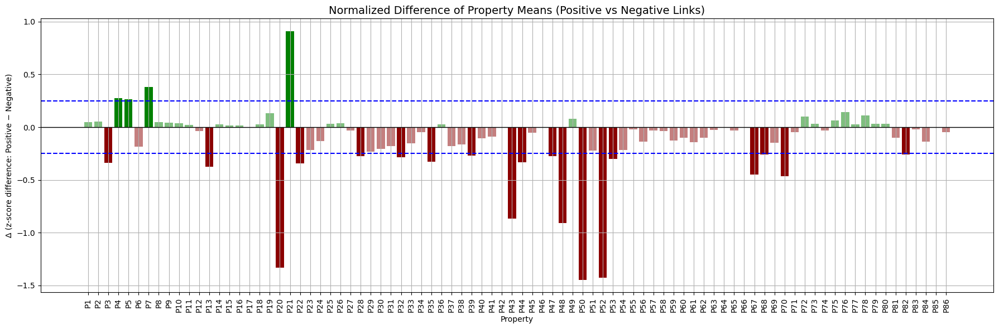

Found 4 properties higher for positive links (zΔ > 0.25):
- (z_diff = 0.273) 	 FRACTION_OF_DIGITS
- (z_diff = 0.262) 	 FRACTION_OF_UPPERCASE_CHARACTERS
- (z_diff = 0.382) 	 FRACTION_OF_SPECIAL_CHARACTERS_SUCH_AS_COMMA_EXCLAMATION_MARK_ETC
- (z_diff = 0.911) 	 COMPOUND_SENTIMENT_CALCULATED_BY_VADER

 Found 19 properties higher for negative links (zΔ < -0.25):
- (z_diff = -0.34) 	 FRACTION_OF_ALPHABETICAL_CHARACTERS
- (z_diff = -0.375) 	 FRACTION_OF_STOPWORDS
- (z_diff = -1.33) 	 NEGATIVE_SENTIMENT_CALCULATED_BY_VADER
- (z_diff = -0.346) 	 LIWC_FUNCT
- (z_diff = -0.272) 	 LIWC_SHEHE
- (z_diff = -0.287) 	 LIWC_VERBS
- (z_diff = -0.326) 	 LIWC_PRESENT
- (z_diff = -0.27) 	 LIWC_CONJ
- (z_diff = -0.867) 	 LIWC_SWEAR
- (z_diff = -0.33) 	 LIWC_SOCIAL
- (z_diff = -0.273) 	 LIWC_HUMANS
- (z_diff = -0.909) 	 LIWC_AFFECT
- (z_diff = -1.448) 	 LIWC_NEGEMO
- (z_diff = -1.425) 	 LIWC_ANGER
- (z_diff = -0.302) 	 LIWC_SAD
- (z_diff = -0.451) 	 LIWC_BIO
- (z_diff = -0.259) 	 LIWC_BODY
- (z_diff = -0.465

In [6]:
threshold_zdiff = 0.25
avg_z_diffs = evaluate_props_norm_diffs(interactions_df, threshold_zdiff)

Combining our qualitative choice of what defines toxicity with the will to mainly use properties that prove to appear in negative hyperlinks only, below is our final choice of the toxicity_metric. Note that all these properties represent ratios (values between 0 and 1).

Our `TOXICITY_SCORE` metric will be a combination of all these properties.

For this initial exploration, we define the continuous `TOXICITY_SCORE` as a **weighted average** of the retained properties. The current weights are derived from intuitive coefficients based on established literature in toxicity and destructive discourse, prioritizing a fast, interpretable metric that reflects our working definition of toxicity. While this approach is **simple and effective for preliminary analysis**, in the future **we plan to explore more advanced options**, such as performing Logistic Regression on a small, manually labeled subset of the data to derive statistically optimized weights, for example. It can also turn out better to do more than a simple linear combination and we might use interaction terms and non-linear functions of property scores.

Mathematically, `TOXICITY_SCORE` will therefore range from -1 to 1.

In [7]:
interactions_df["LINK_SENTIMENT_ADJUST"] = (1 - (interactions_df["LINK_SENTIMENT"] + 1)/2)/4

tox_props = pd.DataFrame([
    [-3, "FRACTION_OF_DIGITS"],
    [0, "LINK_SENTIMENT_ADJUST"],
    [1, "FRACTION_OF_STOPWORDS"],
    [5, "NEGATIVE_SENTIMENT_CALCULATED_BY_VADER"],
    [-5, "LIWC_CAUSE"],
    [-5, "LIWC_INSIGHT"],
    [5, "LIWC_SWEAR"],
    [1, "LIWC_SOCIAL"],
    [1, "LIWC_HUMANS"],
    [0, "LIWC_AFFECT"],
    [1, "LIWC_NEGEMO"],
    [5, "LIWC_ANGER"],
    [1, "LIWC_SEXUAL"]
    ],
    columns = ["weight", "name"])

# Normalize weights
tox_props["weight (normd)"] = tox_props["weight"] / tox_props["weight"].abs().sum() 
#display(tox_props)

interactions_df["TOXICITY_SCORE"] = (interactions_df[tox_props["name"].to_list()].values * tox_props["weight (normd)"].to_list()).sum(axis = 1)

interactions_df.head()

,SOURCE_SUBREDDIT,TARGET_SUBREDDIT,POST_ID,TIMESTAMP,LINK_SENTIMENT,NUMBER_OF_CHARACTERS,NUMBER_OF_CHARACTERS_WITHOUT_COUNTING_WHITE_SPACE,FRACTION_OF_ALPHABETICAL_CHARACTERS,FRACTION_OF_DIGITS,FRACTION_OF_UPPERCASE_CHARACTERS,...,LIWC_MONEY,LIWC_RELIG,LIWC_DEATH,LIWC_ASSENT,LIWC_DISSENT,LIWC_NONFLU,LIWC_FILLER,TYPE,LINK_SENTIMENT_ADJUST,TOXICITY_SCORE
0,agitation,changemyview,1u5cj7s,2013-12-31 16:20:20,1,102.0,91.0,0.843137,0.000000,0.088235,...,0.0,0.0,0.0000,0.0,0.0,0.000000,0.000000,title,0.0,0.008514
1,rddtgaming,rddtrust,1u4pzzs,2013-12-31 16:39:18,1,25.0,23.0,0.760000,0.000000,0.440000,...,0.0,0.0,0.0000,0.0,0.0,0.000000,0.000000,title,0.0,0.000000
2,leagueoflegends,teamredditteams,1u4nrps,2013-12-31 16:39:58,1,345.0,298.0,0.756522,0.017391,0.086957,...,0.0,0.0,0.0000,0.0,0.0,0.000000,0.000000,body,0.0,0.019065
3,examplesofevil,pics,1u5lhas,2013-12-31 16:40:29,1,96.0,83.0,0.833333,0.000000,0.062500,...,0.0,0.0,0.0625,0.0,0.0,0.000000,0.000000,title,0.0,0.021591
4,nfl,cfb,1u4sjvs,2013-12-31 17:37:55,1,1124.0,949.0,0.772242,0.001779,0.057829,...,0.0,0.0,0.0000,0.0,0.0,0.020833,0.005208,body,0.0,0.010149


Let's visualize our new metric empirical distribution.

count    858488.000000
mean          0.016344
std           0.023457
min          -0.113636
25%           0.002127
50%           0.009925
75%           0.023687
max           0.416061
Name: TOXICITY_SCORE, dtype: float64


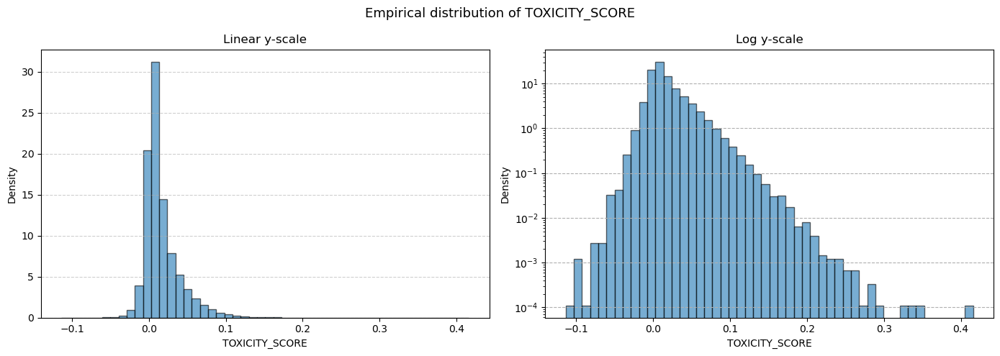

In [8]:
plot_empirical_distribution(interactions_df["TOXICITY_SCORE"], "TOXICITY_SCORE")

Although theoretically ranging from -1 to 1 by construction, we observe that `TOXICITY_SCORE` only take values between approx. -0.1 and 0.4. This is however not a problem because we later introduce multiple centering and scaling operations.

We now have a reliable, continuous measure of toxicity. But it's not necessarily easy to interpret it directly... We would like to accompany this continuous metric with a binary classification: "Is this toxicity score high? In other words, is this message toxic?"

<div style="border: 2px solid #ff0000ff; border-radius: 10px; padding: 10px; display: inline-block; width: 90%; box-sizing: border-box;">
<code>TOXICITY_CAT</code>: categorical metric that classifies posts as toxic (0) or toxic (1), after passing a threshold on <code>TOXICITY_SCORE</code>. 
</div>

For now, the threshod above which messages are flagged as toxic is the quantile-75 of the toxicity scores distribution. That is, **we mark as significantly toxic the top 25% messages with highest score**. While this is a reasonable and consistent approach, this threshold can be better set in the future and we will probably explore better ways to classify messages.

In [9]:
threshold_toxicity = interactions_df["TOXICITY_SCORE"].quantile(0.75)
print("75% quantile threshold:", threshold_toxicity)

interactions_df["TOXICITY_CAT"] = (interactions_df["TOXICITY_SCORE"] >= threshold_toxicity).astype(int)

75% quantile threshold: 0.02368686868687879


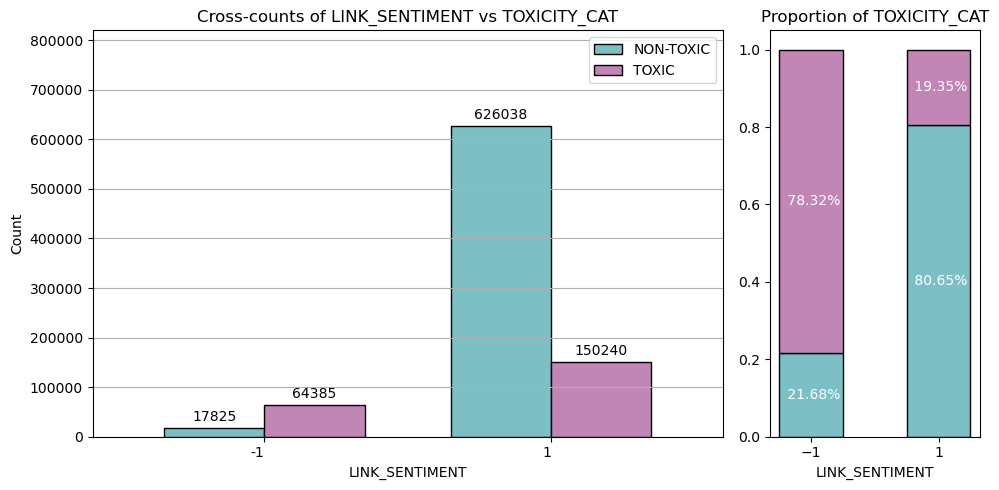

In [10]:
cross_count_SENTIMENT_TOXICITY(interactions_df)

At first, it appears that the majority of toxic messages are actualy labeled positive, which is not desirable as we explicited that, in our context, toxicity only comes with negativity. 

However, looking at the **proportions** of toxicity in each sentiment class (right barplot), we see that around 78% of negative messages are labeled toxic, while only 19% of positive messages were. Negative messages are much more likely to be toxic (which makes sense based on the properties we retained to define toxicity).

In the next cell, we enforce the rule that only messages with negative sentiment (`LINK_SENTIMENT` = −1) can be classified as toxic (`TOXICITY_CAT` = 1). This decision is based on a conceptual definition of toxicity as hostile, harmful, or abusive discourse, which fundamentally requires a negative emotional valence. Although positive/neutral-sentiment messages may sometimes contain high levels of features like swearing or anger, classifying them as toxic would introduce significant false positives that do not align with the standard understanding of online harassment or abuse.

**Remark**

The continuous `TOXICITY_SCORE` is preserved even for the links that are ultimately filtered out by the sentiment check. This score serves as a crucial linguistic feature intensity metric, quantifying the sheer presence of aggressive or low-quality language features (e.g., swearing, anger, simplicity) independent of the link's overall "true" sentiment. By keeping the raw score, we retain valuable information for later analysis, such as comparing the distribution of strong language features across both toxic (negative sentiment) and non-toxic (positive sentiment) messages, which can reveal linguistic patterns related to intense discourse beyond just negative intent.

In [11]:
interactions_df["TOXICITY_CAT"] = ((interactions_df["TOXICITY_CAT"] == 1) & (interactions_df["LINK_SENTIMENT"] == -1)).astype(int)

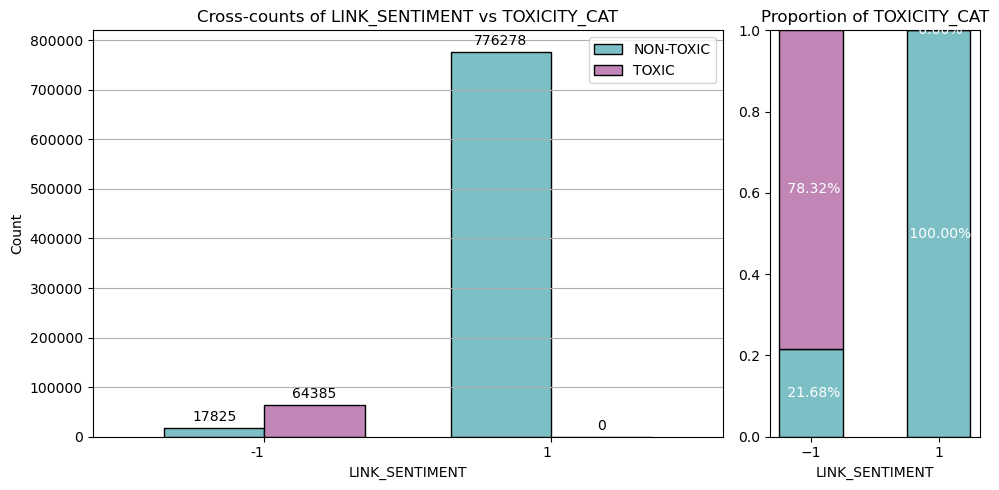

In [12]:
# Sanity check (to verify elimination of false positives)
cross_count_SENTIMENT_TOXICITY(interactions_df)

Let's see how much toxic posts we detected over the entire period. The following plot aggregates over all subreddits and averages monthly, but acts as a quick sanity check to see if the count stays coherent over time.

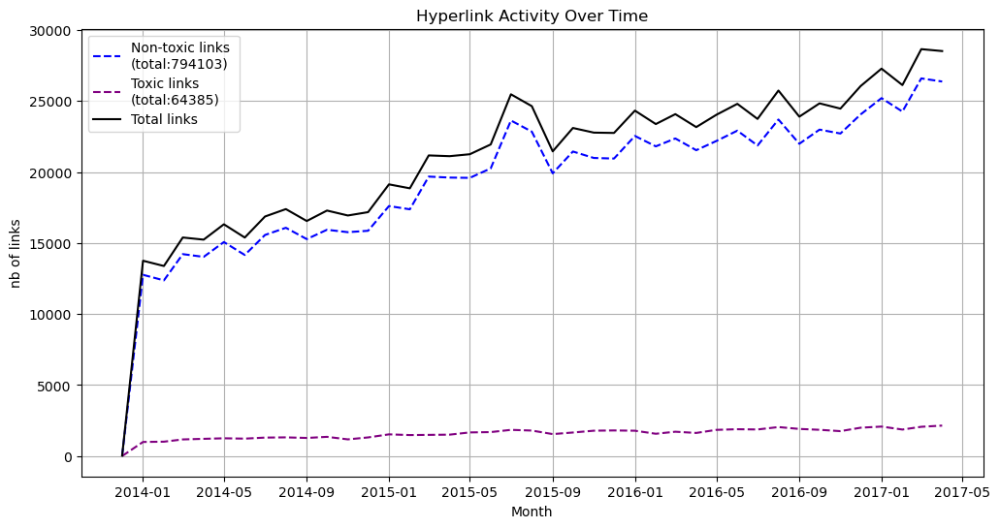

In [13]:
interactions_df["year_month"] = interactions_df["TIMESTAMP"].dt.to_period("M").dt.to_timestamp()

links_over_time_sent = (
    interactions_df.groupby(["year_month", "TOXICITY_CAT"])
    .size()
    .reset_index(name="n_links")
)

links_over_time_pivot = links_over_time_sent.pivot(
    index="year_month", columns="TOXICITY_CAT", values="n_links"
).fillna(0)

links_over_time_pivot["total"] = links_over_time_pivot.sum(axis=1)
toxicity_counts = interactions_df["TOXICITY_CAT"].value_counts()

plt.figure(figsize=(12, 6))
plt.plot(links_over_time_pivot.index, links_over_time_pivot[0], label=f"Non-toxic links \n(total:{toxicity_counts[0]})", color='blue', linestyle = '--')
plt.plot(links_over_time_pivot.index, links_over_time_pivot[1], label=f"Toxic links \n(total:{toxicity_counts[1]})", color='purple', linestyle = '--')
plt.plot(links_over_time_pivot.index, links_over_time_pivot["total"], label="Total links", color="black")

plt.title("Hyperlink Activity Over Time")
plt.xlabel("Month")
plt.ylabel("nb of links")
plt.legend()
plt.grid(True)
plt.show()

### 1.2.2 Supporting and Derived Metrics 

<div style="border: 2px solid #ff0000ff; border-radius: 10px; padding: 10px; display: inline-block; width: 90%; box-sizing: border-box;">

 
**Count Metrics:**

(Following metrics can be restricted to a specified time window)
- `TOXICITY_COUNT`: Number of posts classified toxic during the time window:
    - if the time window is `'overall'`, this is simply the global count of toxic posts over the entire dataset.
    - if the time window is `'monthly'` or `'yearly'`, this is the count of toxic posts computed for each month or year separately (e.g., for `'monthly', the count of toxic posts in June 2023).
- `NON_TOXICITY_COUNT`: Number of posts classified toxic during the time window:
    - if the time window is `'overall'`, this is simply the global count of non-toxic posts over the entire dataset.
    - if the time window is `'monthly'` or `'yearly'`, this is the count of non-toxic posts computed for each month or year separately (e.g., for `'monthly', the count of non-toxic posts in June 2023).
- `TOTAL_COUNT`: Number of posts (toxic + non-toxic) during the time window:
    - if the time window is `'overall'`, this is simply the global count of posts over the entire dataset.
    - if the time window is `'monthly'` or `'yearly'`, this is the count of posts computed for each month or year separately (e.g., for `'monthly', the count of posts in June 2023).

These metrics also act as a foundation for the following rate-based metrics.`



</div>

In [14]:
toxic_count = compute_toxic_count(interactions_df, time_window='yearly')
non_toxic_count = compute_non_toxic_count(interactions_df, time_window='yearly')
total_count = compute_total_count(interactions_df, time_window='yearly')

count_metrics_df = pd.concat([toxic_count, non_toxic_count, total_count], axis=1)
count_metrics_df.columns = ['TOXICITY_COUNT', 'NON_TOXICITY_COUNT', 'TOTAL_COUNT']
count_metrics_df.head()

c:\Users\coudu\OneDrive\Documents\Work\Master\Ma3\ADA\ada-2025-project-adastra-1\src\utils\compute_metric_utils.py:263: FutureWarning: 'Y' is deprecated and will be removed in a future version, please use 'YE' instead.
  series = data.set_index("TIMESTAMP")["TOXICITY_SCORE"].gt(TOXICITY_THRESHOLD).resample("Y").sum()
c:\Users\coudu\OneDrive\Documents\Work\Master\Ma3\ADA\ada-2025-project-adastra-1\src\utils\compute_metric_utils.py:301: FutureWarning: 'Y' is deprecated and will be removed in a future version, please use 'YE' instead.
  series = data.set_index("TIMESTAMP")["TOXICITY_SCORE"].lt(TOXICITY_THRESHOLD).resample("Y").sum()
c:\Users\coudu\OneDrive\Documents\Work\Master\Ma3\ADA\ada-2025-project-adastra-1\src\utils\compute_metric_utils.py:339: FutureWarning: 'Y' is deprecated and will be removed in a future version, please use 'YE' instead.
  series = data.set_index("TIMESTAMP").resample("Y").size()


,TOXICITY_COUNT,NON_TOXICITY_COUNT,TOTAL_COUNT
TIMESTAMP,,,
2013-12-31,3,31,34
2014-12-31,46272,145417,191689
2015-12-31,65671,198000,263671
2016-12-31,73314,219202,292516
2017-12-31,26660,83918,110578


<div style="border: 2px solid #ff0000ff; border-radius: 10px; padding: 10px; display: inline-block; width: 90%; box-sizing: border-box;">

**Rate-Based Metrics:**

To quantify frequency and ratios of toxic behavior in a given time window.

- `TOXICITY_RATE`: Proportion of toxic source messages in a time window, calculated as `TOXIC_COUNT` divided by `TOTAL_COUNT` (Range: 0–1):
    - if the time window is `'overall'`, this is simply the overall proportion of toxic posts over the entire dataset.
    - if the time window is `'monthly'` or `'yearly'`, this is the proportion of toxic posts computed for each month or year separately (e.g., for `'monthly', the proportion of toxic posts in June 2023).
- `TOXICITY_ODDS`: Alternative measure calculated as `TOXIC_COUNT` divided by `NON_TOXIC_COUNT`. Could be used to model odds and log-odds for logistic models in the following steps of the project:
    - if the time window is `'overall'`, this is simply the overall odds of toxic posts over the entire dataset.
    - if the time window is `'monthly'` or `'yearly'`, this is the odds of toxic posts computed for each month or year separately (e.g., for `'monthly', the odds of toxic posts in June 2023).
</div>

In [15]:
toxicity_rate = compute_toxicity_rate(interactions_df, time_window='yearly')
toxicity_odds = compute_toxicity_odds(interactions_df, time_window='yearly')

rate_metrics_df = pd.concat([toxicity_rate, toxicity_odds], axis=1)
rate_metrics_df.columns = ['TOXICITY_RATE', 'TOXICITY_ODDS']
rate_metrics_df.head()

c:\Users\coudu\OneDrive\Documents\Work\Master\Ma3\ADA\ada-2025-project-adastra-1\src\utils\compute_metric_utils.py:263: FutureWarning: 'Y' is deprecated and will be removed in a future version, please use 'YE' instead.
  series = data.set_index("TIMESTAMP")["TOXICITY_SCORE"].gt(TOXICITY_THRESHOLD).resample("Y").sum()
c:\Users\coudu\OneDrive\Documents\Work\Master\Ma3\ADA\ada-2025-project-adastra-1\src\utils\compute_metric_utils.py:339: FutureWarning: 'Y' is deprecated and will be removed in a future version, please use 'YE' instead.
  series = data.set_index("TIMESTAMP").resample("Y").size()
c:\Users\coudu\OneDrive\Documents\Work\Master\Ma3\ADA\ada-2025-project-adastra-1\src\utils\compute_metric_utils.py:263: FutureWarning: 'Y' is deprecated and will be removed in a future version, please use 'YE' instead.
  series = data.set_index("TIMESTAMP")["TOXICITY_SCORE"].gt(TOXICITY_THRESHOLD).resample("Y").sum()
c:\Users\coudu\OneDrive\Documents\Work\Master\Ma3\ADA\ada-2025-project-adastra-1\sr

,TOXICITY_RATE,TOXICITY_ODDS
TIMESTAMP,,
2013-12-31,0.088235,0.096774
2014-12-31,0.241391,0.318202
2015-12-31,0.249064,0.331672
2016-12-31,0.250632,0.334459
2017-12-31,0.241097,0.317691


<div style="border: 2px solid #ff0000ff; border-radius: 10px; padding: 10px; display: inline-block; width: 90%; box-sizing: border-box;">

**Rollingly Normalized Score Metric:**

<code>TOXICITY_SCORE_ROLLZ</code>: continuous metric <code>TOXICITY_SCORE</code>, normalized on a lagging rolling window (that is, at each date it is centered on its rolling average and divided by its rolling std). No look-ahead bias is applied (the metric can be used for future prediction task just like the original score). For now, we keep the temporal window to 1 year.

The use of this last metric is to facilitate detecting **toxicity bursts**: when <code>TOXICITY_SCORE_ROLLZ</code> passes above a threshold (for example 2), it means that this post is more toxic by 2*std than the toxicity mean of all posts of last year. 
</div>

In [16]:
rolling_window = "365D" # The time window can be adjusted as needed

interactions_df["TOXICITY_SCORE_ROLLZ"] = (
    (interactions_df["TOXICITY_SCORE"] -
     interactions_df.rolling(rolling_window, on="TIMESTAMP")["TOXICITY_SCORE"].mean())
    / interactions_df.rolling(rolling_window, on="TIMESTAMP")["TOXICITY_SCORE"].std()
)

<div style="border: 2px solid #ff0000ff; border-radius: 10px; padding: 10px; display: inline-block; width: 90%; box-sizing: border-box;">

**General Normalization Metrics:**

To contextualize toxicity scores within recent history (i.e., the considered time window).

- `BASE_TOXICTY_OFFSET`: Mean of `TOXICITY_SCORE` within the time window:
    - if the time window is `'overall'`, this is simply the global mean of the score over the entire dataset.
    - if the time window is `'monthly'` or `'yearly'`, this is the mean toxicity score computed for each month or year separately (e.g., for `'monthly'`, the mean toxicity score of all posts in June 2023).
- `TOXICITY_STD`: Standard deviation of `TOXICITY_SCORE` within the time window:
    - if the time window is `'overall'`, this is simply the global std of the score over the entire dataset.
    - if the time window is `'monthly'` or 'yearly', this is the std toxicity score computed for each month or year separately (e.g., for `'monthly'`, the std of toxicity score of all posts in June 2023).
- `TOXICITY_CONTEXT_ZSCORE`: Z-score of `TOXICITY_SCORE` within the time window:
    - if the time window is `'overall'`, this is each post's toxicity score standardized using the global mean and std.
    - if the time window is `'monthly'` or `'yearly'`, this is each post's toxicity score standardized using the mean and std of the corresponding month or year (e.g., for `'monthly'`, all posts in June 2023 are standardized using the mean and std of toxicity scores of June 2023).
</div>



In [17]:
base_offset = compute_base_toxicity_offset(interactions_df, 'yearly')
tox_std = compute_toxicity_std(interactions_df, 'yearly')
context_zscore = compute_toxicity_context_zscore(interactions_df, 'yearly')

gen_norm_metrics_df = pd.concat([base_offset, tox_std], axis=1)
gen_norm_metrics_df.columns = ['BASE_TOXICITY_OFFSET', 'TOXICITY_STD']

gen_norm_metrics_df.head(10)

c:\Users\coudu\OneDrive\Documents\Work\Master\Ma3\ADA\ada-2025-project-adastra-1\src\utils\compute_metric_utils.py:110: FutureWarning: 'Y' is deprecated and will be removed in a future version, please use 'YE' instead.
  series = data.set_index("TIMESTAMP").resample("Y")["TOXICITY_SCORE"].mean()
c:\Users\coudu\OneDrive\Documents\Work\Master\Ma3\ADA\ada-2025-project-adastra-1\src\utils\compute_metric_utils.py:158: FutureWarning: 'Y' is deprecated and will be removed in a future version, please use 'YE' instead.
  series = data.set_index("TIMESTAMP").resample("Y")["TOXICITY_SCORE"].std()
c:\Users\coudu\OneDrive\Documents\Work\Master\Ma3\ADA\ada-2025-project-adastra-1\src\utils\compute_metric_utils.py:110: FutureWarning: 'Y' is deprecated and will be removed in a future version, please use 'YE' instead.
  series = data.set_index("TIMESTAMP").resample("Y")["TOXICITY_SCORE"].mean()
c:\Users\coudu\OneDrive\Documents\Work\Master\Ma3\ADA\ada-2025-project-adastra-1\src\utils\compute_metric_util

,BASE_TOXICITY_OFFSET,TOXICITY_STD
TIMESTAMP,,
2013-12-31,0.009410,0.019562
2014-12-31,0.016029,0.022846
2015-12-31,0.016474,0.023332
2016-12-31,0.016527,0.023819
2017-12-31,0.016097,0.023829


In [18]:
context_zscore.head()

0   -0.045794
1   -0.481001
2    0.493553
3    0.622692
4    0.037780
dtype: float64

<div style="border: 2px solid #ff0000ff; border-radius: 10px; padding: 10px; display: inline-block; width: 90%; box-sizing: border-box;">

**Directional Metrics:**

These metrics are subreddit-specific and will allow to explore community behaviors in a given time window.

- `TOXICITY_OUT`: Toxic links sent by a subreddit (aggressor behavior) in a time window:
    - if the time window is `'overall'`, this is simply the overall count of toxic posts sent by the subreddit over the entire dataset.
    - if the time window is `'monthly'` or `'yearly'`, this is the count of toxic posts sent by the subreddit computed for each month or year separately (e.g., for `'monthly', the count of toxic posts sent by the subreddit in June 2023).
- `TOXICITY_IN`: Toxic links received by a subreddit (victim/target behavior) in a time window:
    - if the time window is `'overall'`, this is simply the overall count of toxic posts received by the subreddit over the entire dataset.
    - if the time window is `'monthly'` or `'yearly'`, this is the count of toxic posts received by the subreddit computed for each month or year separately (e.g., for `'monthly', the count of toxic posts received by the subreddit in June 2023).
- `TOXICITY_BALANCE`: Net toxicity = `TOXICITY_OUT - TOXICITY_IN` in a time window:
    - if the time window is `'overall'`, this is simply the overall net toxicity of the subreddit over the entire dataset.
    - if the time window is `'monthly'` or `'yearly'`, this is the net toxicity of the subreddit computed for each month or year separately (e.g., for `'monthly', the net toxicity of the subreddit in June 2023).
- `RECIPROCAL_TOXICITY`: Bidirectional toxic relationships between subreddit pairs which corresponds to the number of bidirectional edges in the toxic interaction graph in a time window:
    - if the time window is `'overall'`, this is simply the overall count of bidirectional toxic edges between a selected subreddit and its pairs over the entire dataset.
    - if the time window is `'monthly'` or `'yearly'`, this is the count of bidirectional toxic edges between a selected subreddit and its pairs computed for each month or year separately (e.g., for `'monthly', the count of bidirectional toxic edges between subreddit pairs in June 2023).
</div>

In [19]:
toxicity_out_nfl = compute_toxicity_out(interactions_df, subreddit_name='nfl', time_window='yearly')
toxicity_in_nfl = compute_toxicity_in(interactions_df, subreddit_name='nfl', time_window='yearly')
toxicity_balance_nfl = compute_toxicity_balance(interactions_df, subreddit_name='nfl', time_window='yearly')

directional_metrics_nfl_df = pd.concat([toxicity_out_nfl, toxicity_in_nfl, toxicity_balance_nfl], axis=1)
directional_metrics_nfl_df.columns = ['TOXICITY_OUT_NFL', 'TOXICITY_IN_NFL', 'TOXICITY_BALANCE_NFL']
directional_metrics_nfl_df.head()

c:\Users\coudu\OneDrive\Documents\Work\Master\Ma3\ADA\ada-2025-project-adastra-1\src\utils\compute_metric_utils.py:263: FutureWarning: 'Y' is deprecated and will be removed in a future version, please use 'YE' instead.
  series = data.set_index("TIMESTAMP")["TOXICITY_SCORE"].gt(TOXICITY_THRESHOLD).resample("Y").sum()
c:\Users\coudu\OneDrive\Documents\Work\Master\Ma3\ADA\ada-2025-project-adastra-1\src\utils\compute_metric_utils.py:263: FutureWarning: 'Y' is deprecated and will be removed in a future version, please use 'YE' instead.
  series = data.set_index("TIMESTAMP")["TOXICITY_SCORE"].gt(TOXICITY_THRESHOLD).resample("Y").sum()
c:\Users\coudu\OneDrive\Documents\Work\Master\Ma3\ADA\ada-2025-project-adastra-1\src\utils\compute_metric_utils.py:263: FutureWarning: 'Y' is deprecated and will be removed in a future version, please use 'YE' instead.
  series = data.set_index("TIMESTAMP")["TOXICITY_SCORE"].gt(TOXICITY_THRESHOLD).resample("Y").sum()
c:\Users\coudu\OneDrive\Documents\Work\Mast

,TOXICITY_OUT_NFL,TOXICITY_IN_NFL,TOXICITY_BALANCE_NFL
TIMESTAMP,,,
2013-12-31,0,1,-1
2014-12-31,16,236,-220
2015-12-31,27,234,-207
2016-12-31,60,266,-206
2017-12-31,9,121,-112


### 1.2.3 Potential Metrics to implement

<div style="border: 2px solid #ff0000ff; border-radius: 10px; padding: 10px;  display: inline-block; width: 90%; box-sizing: border-box;">
 
**Advanced Linguistic Metrics:**

To focus on **specific properties** of what was used to define toxicity. Could be useful and interesting when analysing the propagation of the negativity among subreddits.

- `PERSONAL_ATTACK_SCORE`: LIWC_You + LIWC_Negemo combinations.
- `RATIONAL_DISCOURSE_SCORE`: LIWC_CogMech + LIWC_Cause. 
- `COMPLEXITY_SCORE`: Readability + word length + vocabulary richness.

</div>

<div style="border: 2px solid #ff0000ff; border-radius: 10px; padding: 10px; display: inline-block; width: 90%; box-sizing: border-box;">
 
**Temporal Metrics:**
- `TOXICITY_VELOCITY`: Rate of change in toxicity over time (Δtoxicity_rate / Δtime)
- `TOXICITY_ACCELERATION`: Second derivative (change in velocity)
- `TOXICITY_PERSISTENCE`: Duration of sustained toxic behavior (consecutive toxic periods)

</div>

## 1.3 Network Construction and Representation

1. Build temporal network snapshots (monthly/yearly windows as shorter windows seem unreasonable given the data)  
2. Build directed graphs for each time period
3. Compute node edge attributes: degrees, toxicity metrics, network centrality measures, eigenvector centrality
4. Store as adjacency lists or graph objects for analysis

### 1.3.1 Computing overall mean toxicity score

To get an overall idea of whether we can detect clusters of toxic subreddits, we compute the mean toxicity score of the interactions going out of each subreddit, and use the embeddings to map them.

In [20]:
# === Compute mean toxicity for each source subreddit ===
mean_toxicity = (
    interactions_df.groupby("SOURCE_SUBREDDIT")["TOXICITY_SCORE"]
    .mean()
    .rename("mean_toxicity_score")
)

# === Quick sanity check ===
print(mean_toxicity.head())
print(f"\nTotal subreddits with data: {mean_toxicity.ne(0).sum()} / {len(mean_toxicity)}")

SOURCE_SUBREDDIT
007                 0.000000
07scape             0.015126
07thexpansion       0.025000
098f6bcd4621d373    0.007576
0________0          0.010101
Name: mean_toxicity_score, dtype: float64

Total subreddits with data: 53420 / 55863


### 1.3.2 Mapping most active subreddits mean toxicity score

To obtain a readable and interpretable map (with not too many subreddits), we only keep active subreddits (the ones that have more than 20 outgoing interactions over the time period).
We use UMAP (Uniform Manifold Approximation and Projection) to reduce the dimensionality of the embeddings (300) to a plottable 2D map, to see the proximity between subreddits based on their embedding representations. UMAP is a nonlinear dimensionality reduction technique that preserves both local and global structure in the data, making it well-suited for visualizing complex high-dimensional relationships between subreddits in a 2D space.

c:\Users\coudu\anaconda3\envs\ada\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
c:\Users\coudu\OneDrive\Documents\Work\Master\Ma3\ADA\ada-2025-project-adastra-1\src\utils\network_utils.py:60: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  embeddings_df['x'] = embedding_2d[:, 0]
c:\Users\coudu\OneDrive\Documents\Work\Master\Ma3\ADA\ada-2025-project-adastra-1\src\utils\network_utils.py:61: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a

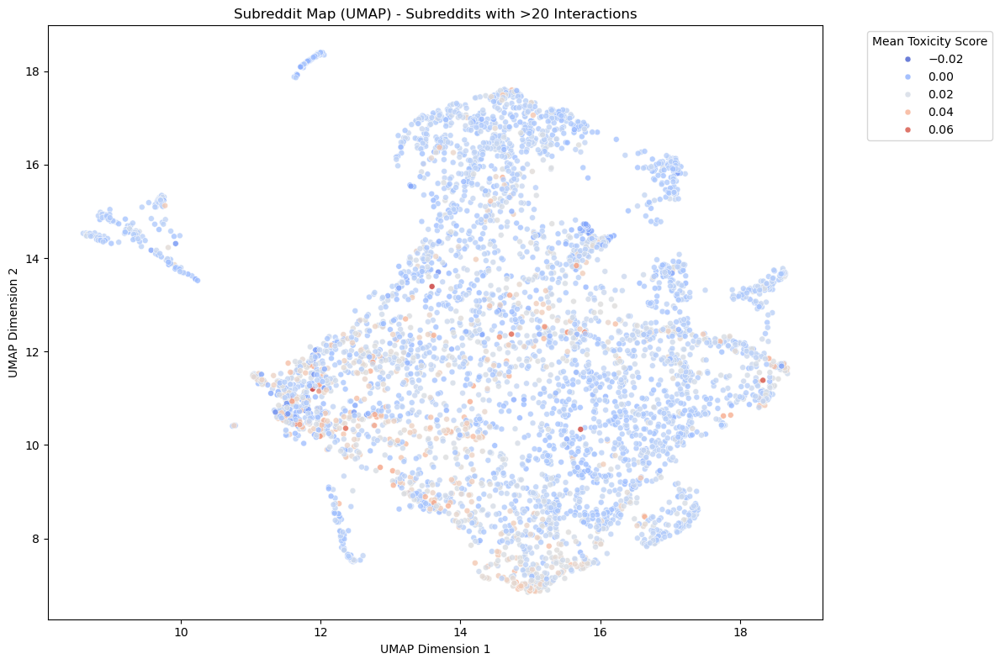

In [21]:
# Use utils function to filter active subreddits and get their embeddings
active_subs, filtered_embeddings = filter_active_subreddits(min_interactions=20)

# Reduce filtered embeddings from 3D to 2D
filtered_embeddings_2d = reduce_embeddings_2d(filtered_embeddings)

# Merge mean toxicity data
embeddings_with_toxicity = filtered_embeddings_2d.merge(
    mean_toxicity, left_on="SUBREDDIT", right_on="SOURCE_SUBREDDIT", right_index=True, how="left"
).fillna(0)

# === Plot ===
plt.figure(figsize=(12, 8))
sns.scatterplot(
    data=embeddings_with_toxicity,
    x="x", y="y",
    hue="mean_toxicity_score",
    palette="coolwarm",   
    s=25,
    alpha=0.8
)
plt.title("Subreddit Map (UMAP) - Subreddits with >20 Interactions")
plt.xlabel("UMAP Dimension 1")
plt.ylabel("UMAP Dimension 2")
plt.legend(title="Mean Toxicity Score", bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

We can already see that some areas have a higher proportion of subreddits with a moderately high mean toxicity score. 
This observation is very broad since it only considers the mean toxicity over the whole period (2.5 years): communities should be easier to observe over a smaller time period, if selected correctly.

### 1.3.3 Monthly evolution of toxicity score

We check whether we can decompose the data into monthly time series by taking advantage of the 'TIMESTAMP' column, still with the most active subreddits, and plot them using an animated UMAP. 
We compute the monthly mean outgoing toxicity score of each subreddit to see their evolution with time.

In [22]:
ani_monthly = animate_evolution(active_subs, filtered_embeddings, freq='M')
HTML(ani_monthly.to_jshtml())

c:\Users\coudu\OneDrive\Documents\Work\Master\Ma3\ADA\ada-2025-project-adastra-1\src\utils\network_utils.py:110: FutureWarning: 'M' is deprecated and will be removed in a future version, please use 'ME' instead.
  .groupby([pd.Grouper(key='TIMESTAMP', freq=freq), 'SOURCE_SUBREDDIT'])


This animation shows fluctuating toxicity scores for most subreddits, but also clusters who keep mostly toxic interactions throughout the whole time period (such as at the bottom left of the main island).

### 1.3.4 Weekly evolution of toxicity score

To later  be able to investigate cascades of toxicity with more precision, we try visualizing weekly evolution of toxicity scores

In [23]:
ani_weekly = animate_evolution(active_subs, filtered_embeddings, freq='W')
HTML(ani_weekly.to_jshtml())

Animation size has reached 21002201 bytes, exceeding the limit of 20971520.0. If you're sure you want a larger animation embedded, set the animation.embed_limit rc parameter to a larger value (in MB). This and further frames will be dropped.


The result is too heavy to be displayed entirely but shows that we are able to study weekly fluctuations of toxicity of subreddits within a certain time window (to be later determined for cascade analysis).

---
# Phase 2: Outbreak Detection and Analysis

## 2.1 Community Exploration and Structure Analysis
- Detect subreddit clusters (who interacts with whom?)
- Characterize each community's baseline behavior
- Track community changes over time

### 2.1.1 Using the Louvain algorithm

The Louvain algorithm is a community detection method that groups nodes in a network into clusters (communities) by maximizing modularity, a measure of how densely connected nodes are within communities compared to between them. In our case, we apply the Louvain algorithm to the toxic interaction graph, where nodes represent subreddits and weighted edges represent the number of toxic interactions between them. This allows us to identify clusters of subreddits that frequently exchange toxic messages, revealing potential toxic communities.

Graph built: 9752 nodes, 32224 toxic edges
Detected 1233 communities.
Detected 123 toxic communities.
     COMMUNITY_ID  SIZE
0              18     2
1              21     1
2              30     2
3              31     2
4              38     1
..            ...   ...
118          1222     2
119          1224     1
120          1226     2
121          1229     2
122          1231     2

[123 rows x 2 columns]
Biggest highly toxic community ID: 863
Number of subreddits in this community: 7


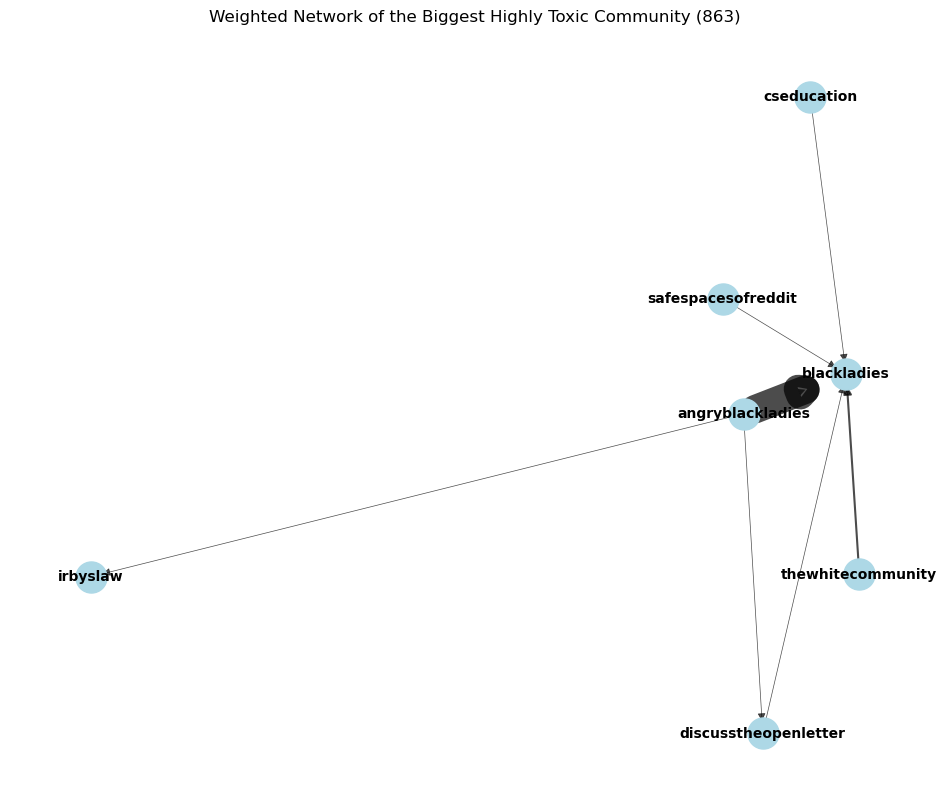

In [24]:
# Only select toxic interactions to build the graph to detect toxic communities
toxic_df = interactions_df[interactions_df["TOXICITY_CAT"] == 1]  # keep only toxic interactions

# Find Louvain communities from toxic interactions and their number of interactions
community_df, toxic_interactions = louvain_communities(toxic_df)

# We consider communities with more than 30% toxic interactions as toxic
toxicity_threshold = 0.3

# Find toxic communities
community_df = get_toxic_communities(community_df, toxicity_threshold)

# Plot the biggest toxic community network
plot_biggest_toxic_community_network(community_df, toxic_interactions)

We observe that the Louvain algorithm mostly finds very small communities (1 or 2 subreddits). 
This is due to the fact that when using the full time period as we did here, toxic interactions are sparse and scattered across time, leading the Louvain algorithm to detect many small, isolated communities. By focusing on a shorter, well-chosen period where toxicity peaks (to be determined later), interactions are denser and more connected, making it easier to identify larger, more cohesive toxic communities.

## 2.2 Case Studies


We aim to depen our comprehension of the toxic events through case studies. That is, by performing an analysis on a specific time period and for a carefully chosen set of subreddits, we expect to highlight previously-discussed and additional behaviors. 
- First, we select an interesting group of subreddits.
    - A typical subreddit part of a clustered behavior (high-volume balanced (hub) - bursty, low-volume victim - mixt, ...) is chosen and its associated closest neighbors are identified. To this set of neighbors, we add the all subreddits interacting with the initially chosen subreddit. Note that only the union is kept, since some of its neighbors may interact with it. This selected subreddit is called the protagonist.
    
<center><img src="Data/images/1sr_group_selection.png" width="1000"/></center>
<center>Figure: Subreddit Group Selection Schematic.</center>

- Second, we take a reduced time window.
    - From daily interactions over the whole time period (January 2014 to April 2017), we assess peaks and compare them with daily negative interactions over the same period. A period of interest is qualitatively picked.
- Third, we assess if the event is toxic or not.
    - The event is defined as the time series in the selected window of the total negative interactions of all subreddits within the chosen group. Its nature is assessed from the daily activity of the group, and most active subreddits (overall and toxic active) are highlighted. From the trend of negative interactions, we decide if this event is a potential toxic one.
- Finally, we analyze the life cycle of the event.
    - We perform a causal inference analysis using the PCMCI algorithm, reconstructing a causal graph between the most active subreddits time series and the protagonist. This allow us to identify catalysts and true actors in the event, as well as attenuators. Furthermore, death of the event is assigned to passive or active.

*Note that in this section, we will refer as 'global' to indicate a temporal state, meaning over the whole time period available in the original dataset. Comparatively, 'total' will be used to speak about the sum of interactions over subreddits (spatial meaning). This is made to avoid confusion between total interactions and global interactions.*
*Note also that the fourth cluster was not explored as a case-study as it is low-volume, and therefore the associated time series contain less exploitable data.*

In [25]:
import warnings
warnings.filterwarnings('ignore', category=FutureWarning, message=".*'H' is deprecated.*")

### 2.2.1 Time Window Identification

An interesting time window is selected based on the trends of interactions over the whole available time period (global). We argue that the trend of total source and total target interactions adds useful information in addition to a simple global toxic interaction trend. Indeed, this allows us to gather information about the dynamic of the focused group (mostly aggressor or victim interactions).
They add key insights for time window selection, and will be verified later on.

Furthermore, this gives some insights about the associated class, shown in the figure here below.
<center><img src="Data/images/2toxic_event_class.png" width="600"/></center>
<center>Figure: Toxic event classes. a) Single Victim, Multiple Prosecutors b) Multiple Victims, Single Prosecutors c) Multiple Victims, Multiple Prosecutors d) Single Victim, Single Prosecutor.</center>

High source interactions indicate multiple victims, and high target interactions indicate multiple prosecutors. Note that cases where two very active subreddits show both high interactions might be confused for c) or d) equally if no further analysis is done. Catalysts subreddits act indirectly on the event (not necessarily through toxic interactions), and are hard to identify. This is the main reason why neighbor subreddits are selected in addition to interacting subreddits, and we argue that these habitual neighbors are the most likely to act as catalysts. However, such complex interlinked social dynamics cannot be guaranteed to be perfectly modelled this way. As for observational studies where external undetected confounders have underlying effects, we cannot construct a causal analysis encapsulating every confounder with 100% certainty. Moreover, while every scenario may exist, we highlight that most of the toxic events happening in reddit tend to c). Note that prosecutors, victims and catalysts can be labelled as 'participants' for generalization.

Additionally, each interaction (toxic or not) can either have an exciting or attenuating effect, and are not represented in the schematic. They will be assessed in the last part (causal analysis), based on positive or negative correlation of time series.

Here below you will find the results for each Case Study, where the protagonists are: 
- bettersubredditdrame (Cluster 0: moderate-volume aggressors)
- science (Cluster 1: moderate-volume victim leaning)
- drama (Cluster 2: high-volume balanced hub)

Where each section is tackled for each of them in order (time window identification, toxic event assessment, life cycle analysis).

In [26]:
run_time_window_identification(interactions_df, case_study_id=1)

**CS1**: The 'bettersubredditdrama' is particular as it was active only for a short period. However, we can see that the toxic-to-nontoxic ratio of interactions in this period is moderately high, and constant. This makes it a potential chronic toxic subreddit in its lifespan. Furthermore, it almost only interacts as a source, validating its 'aggressor' nature found by clustering. 
We conclude that the time window to consider for this case study is between November 10th 2015 and December 25th 2015.

In [27]:
run_time_window_identification(interactions_df, case_study_id=2)

**CS2**: The 'science' subreddit was subject to numerous bursty events. One of them appears as a dominant toxic event over the whole period and could be interesting to investigate for its rapidly changing behavior. Moreover, most of its interactions over the whole time period are as target, indicating a victim nature (same as clustering prediction). We highlight that the nature of the selected peak between April 15th and May 5th is consistent with this observation, meaning it can also be classified as a victim event.

In [28]:
run_time_window_identification(interactions_df, case_study_id=3)

**CS3**: The 'drama' subreddit is one of the most active on reddit. It has a toxic peak resembling the one of bettersubredditdrama, which makes sense from their thematic closeness. However, its number of interactions is way higher and possesses context before and after, making it non only interesting in itself, but also interesting to compare with the first case study. We can see that the number of source interactions is dominant, indicating an aggressor behavior (consistent with clustering). We therefore select a time window slightly larger than the first case study (i.e. from November 1st 2015 to January 1st 2016) in order to take into account bigger time series data.

### 2.2.2 Toxic Event Assesment
Now that the time window of interest has been chosen, we can extract from the interaction dataframe only the subreddits in the group (keyword-based ∪ usual neighbors-based), and only the interactions within this time window.
We thus construct the so called focused_df and the associated focused_subreddits.

In [47]:
focused_df1, focused_subreddits1 = run_init_toxic_event_assessment(interactions_df, case_study_id=1)
focused_df2, focused_subreddits2 = run_init_toxic_event_assessment(interactions_df, case_study_id=2)
focused_df3, focused_subreddits3 = run_init_toxic_event_assessment(interactions_df, case_study_id=3)

-------------------------------------------
Case Study 1 :
451 interacting subreddits found.
42 additional neighboring subreddits found. ( 95.45454545454545 % of neighboring subreddits included.)
-------------------------------------------
-------------------------------------------
Case Study 2 :
158 interacting subreddits found.
9 additional neighboring subreddits found. ( 100.0 % of neighboring subreddits included.)
-------------------------------------------
-------------------------------------------
Case Study 3 :
815 interacting subreddits found.
56 additional neighboring subreddits found. ( 91.80327868852459 % of neighboring subreddits included.)
-------------------------------------------


**CS1:** 451 subreddits were found to be interacting with 'drama' over the focused time window. This suggests a toxic event with multi victims (class b or class c based on the toxic event classes). Some of its typical interacting network (habitual neighbors) were indeed interacting with it in this period. Most of them (95%) were not interacting directly, but may be catalysts. That is, they may have effects on its interacting subreddits (analogue to a confounder variable) without having direct connection with it.

**CS2:** For the 'science' subreddit, 158 other subreddits were found to be interacting with it over the chosen time window. From its victim nature, this suggests a multi-agressor scenario (class a or c based on the toxic event classes). None of its habitual neighbors are part of these interacting subreddits, but may still be catalysts. That is, they may have effects on its interacting subreddits (analogue to a confounder variable) without having direct connection with it.

**CS3:** Numerous subreddits (815) are interacting with the 'drama' subreddit. This makes sense as it is a very active subreddit overall. We also note that some habitual neighbors (8%) are part of the interacting subreddits. Because of its high number of source interactions and the high number of interacting subreddits, we assess that this outbreak is linked to a multi-victim scenario (class b or class c based on the toxic event classes). While 92% of its typical interacting network is not directly interacting in this period of time, they may have effects on its interacting subreddits (analogue to a confounder variable) without having direct connection with it.

#### 2.2.2.1 Total Interactions Over Time
Based on the daily total interactions, we can assess if this event resembles the type previously assigned during clustering:
- Cluster 0: Moderate-volume aggressors,
- Cluster 1: Moderate-volume victim leaning,
- Cluster 2: high-volume balanced hub.

As mentionned previously, this part allows us to discuss if an interaction outbreak indeed appears in the chosen time window. Moreover, the dominance of one type of interaction (source or target) gives information about the class of toxic event it is. In instance, a high source-to-target ratio indicates that most of the focused subreddits interacts towards external subreddits, meaning a typical agressor behavior.

In [30]:
run_daily_interactions(focused_df1, case_study_id=1)

**CS1**: As seen in the global interaction plot, the interactions of 'bettersubredditdrama' are condensed in a short period. We can see more clearly that the total interaction curve overlaps the total source interaction curve, indicating as stated earlier an aggressor behavior. This confirms the clustering belief. Note that a time step of 12h has been set to distinguish more clearly the trends, and to reduce aggregation of data.

In [31]:
run_daily_interactions(focused_df2, case_study_id=2)

**CS2**: In order to identify more precisely the trends and source-to-target interaction ratios, we use a finer time step of 6h in this plot. Data is therefore less aggregated and in addition to the focus on the selected time window, we can assess that the date of concern is around 18:00 on April 23rd 2015. A majority of target interactions shows a victim-type event for the 'science' subreddit, confirming our prior clustering belief. We can also see another interaction outbreak on April 15th 2015, but we need to see the amount of toxic interaction to assess if it is relevant to our study.

In [32]:
run_daily_interactions(focused_df3, case_study_id=3)

**CS3**: From this plot, we can say that the prior belief obtained with clustering is true. A significant amount of source interactions compared to the target ones indeed indicates an aggressor behaviour. Within this focused time window, it is easier to assess that the total number of interactions indeed went up for an extended period (roughly a month). Compared to the first study case, we have a clearer context to compare this outbreak to. Further analysis with the plot of toxic interactions will provide useful information to establish if an extended toxic event indeed took place.

#### 2.2.2.2 Top Subreddit Interactors
In addition to identifying the class of toxic event and the associated behavior cluster, we take a look at the most active subreddits in this context. This allows us to further classify the event from the number of relevant participants, and perform data reduction to pick the most active subreddits in this case. Typically, the source-to-target interaction ratio is highlighted for each of them, allowing us to identify principal participants. Note that their status as prosecutor, victim or catalyst cannot properly be defined as this is based on their interactions, rather than their toxic interactions (which will be studied in the next parts). Linear axes have been kept because of the stacked bar plots, as a y log-axis would have given more visual importance to very small target interactions compared to those on top of high source interactions. Moreover, the point here is to highlight the differences in activeness, which is easier to assess with a linear axis for dominant subreddits.

In [33]:
sr_interaction_count_df1 = run_top_interactors(focused_df1, case_study_id=1)

**CS1:** From this bar plot, we can conclude that this event is indeed a single prosecutor, multi-victims case (case b). The 'bettersubredditdrama' subreddit is clearly interacting exclusively as a source, meaning the toxic interactions it may have are necessarily as source as well. This is most likely a prosecutor, which is interesting considering its short lifespan. We can hypothesize that it was a highly participating actor in propagating toxicity, and we will verify this hypothesis in the top toxic subreddit interactors section.

In [34]:
sr_interaction_count_df2 = run_top_interactors(focused_df2, case_study_id=2)

**CS2:** As conjectured, the 'science' subreddit is a victim during this event. We can also see that other subreddit have a significant number of interactions, some mostly as target ('askscience'), some as target and source equally ('badsocialscience', 'asksciencefiction'), and some completely as source ('brain_damage'). This indicates we are in a multi-victims, multi-aggressors case (case c). We can highlight that the most active source subreddits are thematically opposed to science, with 'brain_damage', 'badsocialscience', 'conspiracy' and 'badscience' showing up in the top 10 interactors. Furthermore, the 'asksciencefiction' might actually be a false positive, as it has the same keyword in its name but might not interact directly with the 'science' subreddit. We need to see if all these subreddits interact in a toxic manner to confirm these statements.

This comes from how our focusing tool is built, it takes every subreddit with a keyword appear in their name. This ensures no false negatives, but also adds false positives. We argue that this is not an issue as the causal analysis will reveal if it is the case. 

In [35]:
sr_interaction_count_df3 = run_top_interactors(focused_df3, case_study_id=3)

**CS3:** This bar plot confirms our prior belief on the nature of the 'drama' subreddit. Indeed, this subreddit has a high source-to-target interaction ratio, indicating an aggressor nature. What is very interesting is that we can see that the 'drama' subreddit is not the most active in his group. We can conjecture that the subreddit with the most impact is 'subredditdrama', followed closely by 'bettersubredditdrama'. This also links this study case to our first one, showing underlying connections. Since the 'bettersubredditdrama' subreddit has no target interaction, it means the bigger subreddit 'subredditdrama' never targeted it. Moreover, this absence of 'subredditdrama' in the first study case indicates that the bigger subreddits don't actually communicate, but rather focus on multiple, smaller victims. This is key in defining the type of toxic event, and suggests that these subreddits are allied against smaller victims.

Note that from how our focusing tool is built, every subreddit with a keyword appearing in their name is selected. This ensures no false negatives, but also adds false positives. We argue that this is not an issue as the causal analysis will reveal if it is the case.

#### 2.2.2.3 Toxic Interactions over Time
Further analysis of toxic interactions is performed in this subsection. The evolution of the total toxic interactions is key in indicating if the interaction outbreak is indeed toxic. Additionally, a moving average is shown to confirm a change in trend. The toxicity nature of an interaction is decided based on their categorical feature presented earlier:
- 'TOXICITY_CAT' == 1

As a reference, we give here below the typical toxic traits over the whole dataframe (not focused).

In [61]:
average_toxicity_traits(interactions_df)

Average daily toxicity: 0.075
Average toxic duration: 161.96 hours


The average toxic duration is the average time separating an interaction labelled as TOXICITY_CAT == 1 and another one labelled as TOXICITY_CAT == 0 for the same subreddit. Even if it is a bit less than a week, one toxic interaction per day for a week should not be considered a toxic event. We define that a significant outbreak of toxicity >> average daily toxicity is a bursty toxic event, and that high daily toxicity levels for a longer period than a week is considered a long-term toxic event.

In [52]:
daily_neg_interaction_df1 = run_toxic_interactions_over_time(focused_df1, case_study_id=1)

**CS1:** It is clear from this plot that the amount of toxic interaction is non-negligible over the selected period. Even if we don't have much context in such a short lifespan, it can be argued that the whole period of existence of this subreddit is equally toxic, and sufficiently toxic to be considered a chronic toxic subreddit. We emphasize that a typical subreddit has globally close to no toxic interaction, while the moving average here is fluctuating around 4 toxic interactions per day. We conclude this is a toxic event, with 'bettersubredditdrama' as the protagonist. Its role in the event will be identified in the next sections.

In [51]:
daily_neg_interaction_df2 = run_toxic_interactions_over_time(focused_df2, case_study_id=2)

**CS2:** From the moving average, we can assess that this is a bursty toxic event. The rest of the context (toxic interactions around the peak) shows that this subreddit is usually not involved in toxic events. We can also say that the previous outbreak seen in the total interaction plot was not a toxic outbreak, but simply an interaction outbreak.

In [54]:
daily_neg_interaction_df3 = run_toxic_interactions_over_time(focused_df3, case_study_id=3)

**CS3:** As for the first study case, this event can be classified a long-term toxic event. The trend given by the 3-day average shows an overall increase in the number of toxic interactions over the course of a month, which is long enough to be considered long-term. Since this subreddit is already on average more toxic than the average, this even more toxic period is considered as a long-term toxic event.

#### 2.2.2.4 Top Toxic Subreddit Interactors
Finally, we add a plot showing the number of toxic interactions for each subreddit. This allow us to identify the most toxic subreddits, and therefore more precisely select the most active participants in terms of toxicity later on. We use here a log scale for the y-axis as we don't have stacked plots, and to improve readability.

In [62]:
run_top_toxic_interactors(focused_df1, case_study_id=1)

**CS1:** As for the top interactors, the 'bettersubredditdrama' subreddit appears as the dominant toxic interactor. This confirms our conjecture about its role as the principal aggressor in its group. The number of toxic interactions, combined with its interactions being mostly as source, makes it a typical hyper aggressor towards multiple victims.

In [40]:
run_top_toxic_interactors(focused_df2, case_study_id=2)

**CS2:** We can see that the 'science' subreddit is still in the top 3 of most toxic interacting subreddits. However, we highlight that the first and second subreddits were not that high in the total interaction bar plot. The previously identified antithetic subreddits do not turn out to be the most toxic in the 'science' group. Nevertheless, their non-toxic interactions could turn out to have an effect on the toxic interactions of the 'science' subreddit, as catalysts would do. Additionally, the number of toxic interactions is very low (5) compared to the number of total interactions (80). This is still a toxic event for the subreddit in itself, but on a different scale. We highlight that this kind of bursty toxic event is common for small subreddits, especially because the average daily toxicity indicates less than 1 out of 10 toxic interactions. Even an outbreak of 5 toxic interactions is relevant in our study, and provides useful data on the different scales of such events.

In [41]:
run_top_toxic_interactors(focused_df3, case_study_id=3)

**CS3:** As in the bar plot of top interactors, 'subredditdrama', 'bettersubredditdrama' and 'drama' dominate as the most active toxic interactors. This further entails their role as major aggressors. We can say they probably form the aforementioned alliance as prosecutors, propagating toxicity to numerous victims without interacting with one another.

### 2.2.3 Life Cycle Analysis
From the previously gathered information, we are now able to select the most active participants, in terms of interactions and toxic interactions. We aim to confirm our beliefs on prosecutors and catalysts, and identify potential attenuators based on the causal inferences on the protagonist subreddit. Using a state-of-the-art algorithm for causal inference on time series, namely PCMCI (Peter and Clark Momentary Conditional Independence) algorithm [3], we can assess the effect of the most active subreddits on the protagonist. 

See below an overview of its working principle. 
PCMCI: Distinguish causal relationships (based on time series data, from spurious correlations) by taking into account autocorrelation and confounding variables.
1) PC Phase
    - Uses a simplified PC algorithm to identify a set of potential parents for each variable
    - For each variable, tests conditional independence with lagged versions of all variables
    - Iteratively removes spurious links by conditioning on increasingly larger sets of past variables
    - Output: A preliminary causal graph with candidate parent sets for each variable

2. MCI Phase
    - Refines the results from the PC phase
    - For each remaining link, performs a more rigorous conditional independence test
    - Conditions on the parents identified in the PC phase to determine if the link is truly causal
    - Tests independence at specific time lags
    - Output: Final causal graph with strength and significance of causal links

<center><img src="Data/images/3PCMCI_algo.png" width="600"/></center>
<center>Figure: PCMCI steps. Red nodes: conditioning set for X³_t; Blue nodes: conditioning set for X¹_t; Star: False Positives. (Adapted from [1])</center>

Different conditional independence tests can be used, including partial correlation (linear gaussian), rank-based/robust partial correlation, GPDC (nonlinear dependence via Gaussian processes), CMIknn (General conditional), Regression Conditional Independence (residual independence after regression) and Partial Correlation with Weighted Least Square. In our case, the robust partial correlation makes more sense, as it is usually used for social interaction data. Note however that it may miss nonlinear dependencies.

Red links are positively correlated and green links are negatively correlated. Colored links are only drawn towards or from the protagonist. Lag is also shown, and indicates the time taken from one time series to affect the pointed node. As mentioned in the early phase of this section, such social links form a complex web of interlinked connections. PCMCI allows us to determine statistical dependence and correlation between time series, but is not a magical tool. The obtained causal graph is a representation of the causal interactions through statistical relevance, based on our assumptions. For example, we only analyze the most active subreddits, while the real connections might be the result of hundreds of low interacting subreddits. Unmodelled confounders indeed have an effect that cannot be seen in this graph, giving a simplified final analysis. This is also why only the protagonist is analyzed, since it reduces the number of links to take into account. We highlight that the graphs we obtain make sense as the effect on one subreddit is never considered from a single source.

The tigramite library is used to perform PCMCI on our time series data (see [2]).






[1]: Causal Discovery with Multivariate Time Series Data (https://medium.com/causality-in-data-science/causal-discovery-with-multivariate-time-series-data-a3f7ffc16747)

[2]: Tigramite Documentation (https://jakobrunge.github.io/tigramite/index.html#)

[3]: Krich, C., Runge, J., Miralles, D. G., Migliavacca, M., Perez-Priego, O., El-Madany, T., ... & Mahecha, M. D. (2020). Estimating causal networks in biosphere–atmosphere interaction with the PCMCI approach. Biogeosciences, 17(4), 1033-1061.

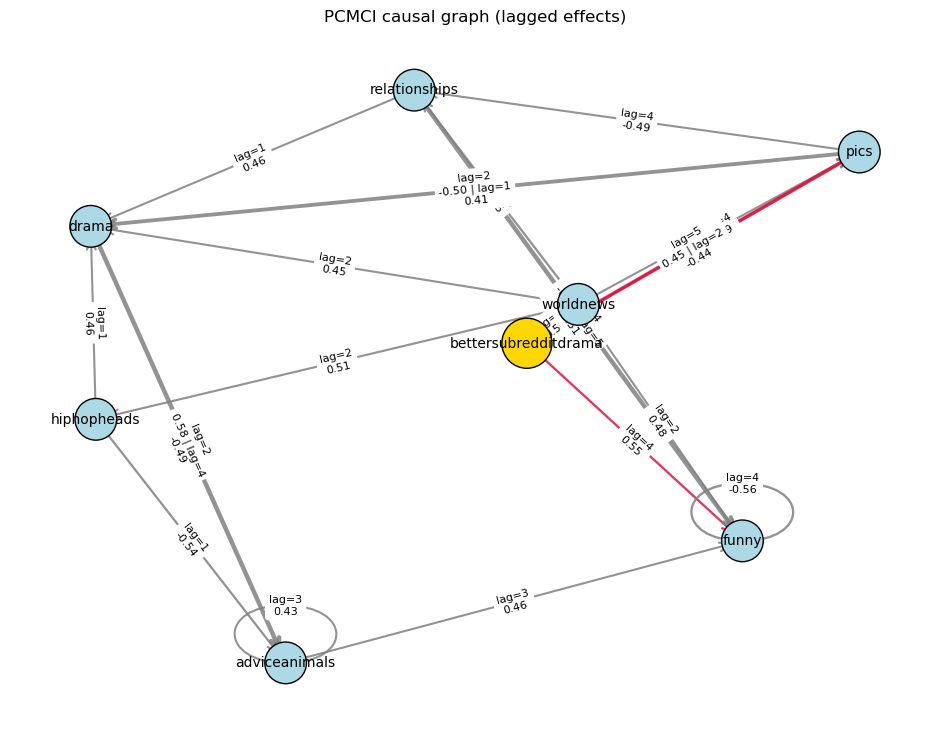

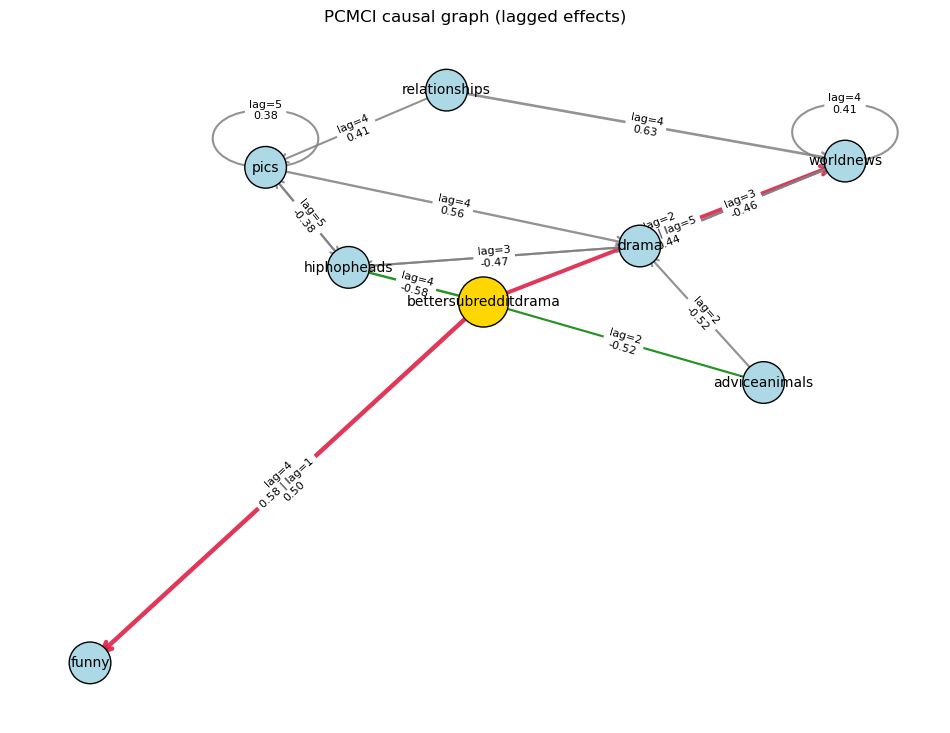

In [68]:
edges1, edges_neg1, finer_focused_subreddits1 = run_pcmci_analysis(daily_neg_interaction_df1, focused_subreddits1, sr_interaction_count_df1, interactions_df, case_study_id=1)

**CS1:**

c:\Users\coudu\anaconda3\envs\ada\Lib\site-packages\tigramite\independence_tests\robust_parcorr.py:402: RuntimeWarning:

divide by zero encountered in log



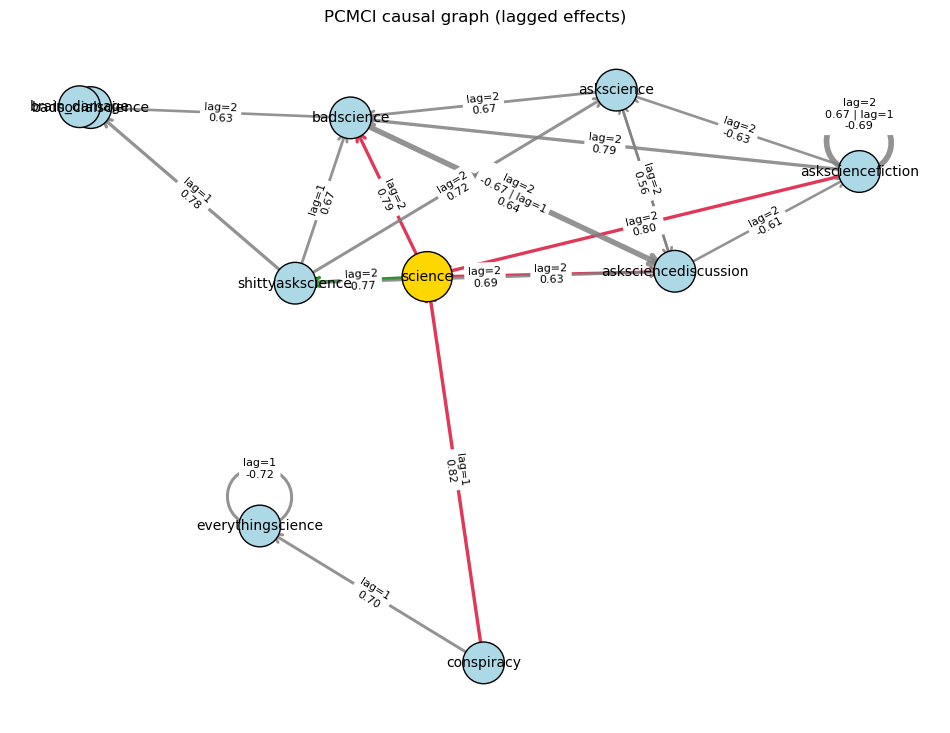

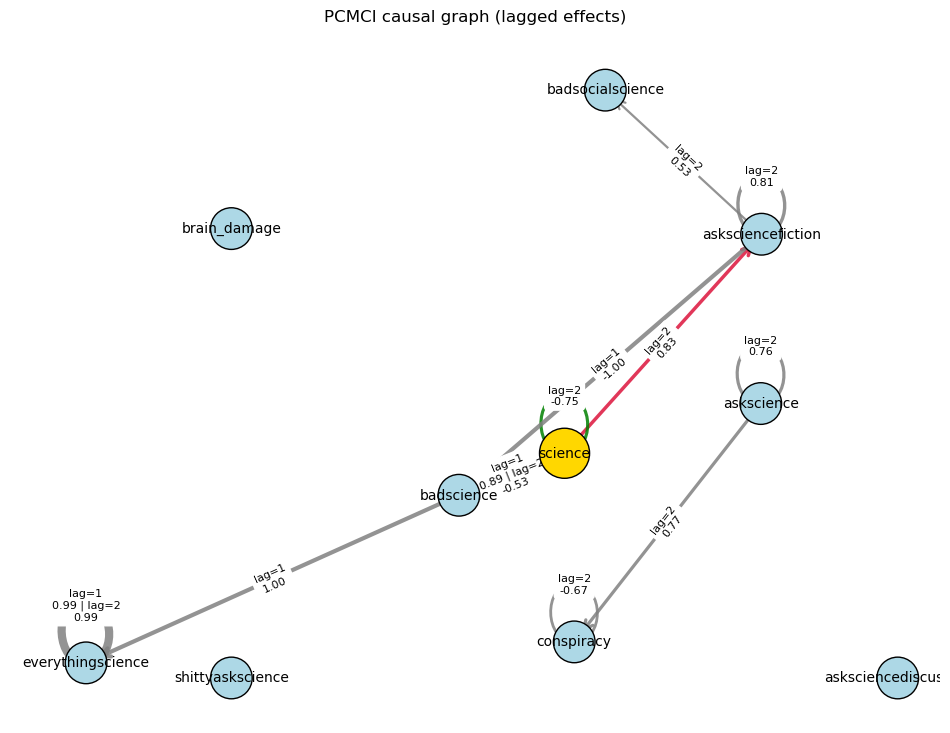

In [69]:
edges2, edges_neg2, finer_focused_subreddits2 = run_pcmci_analysis(daily_neg_interaction_df2, focused_subreddits2, sr_interaction_count_df2, interactions_df, case_study_id=2)

**CS2:**

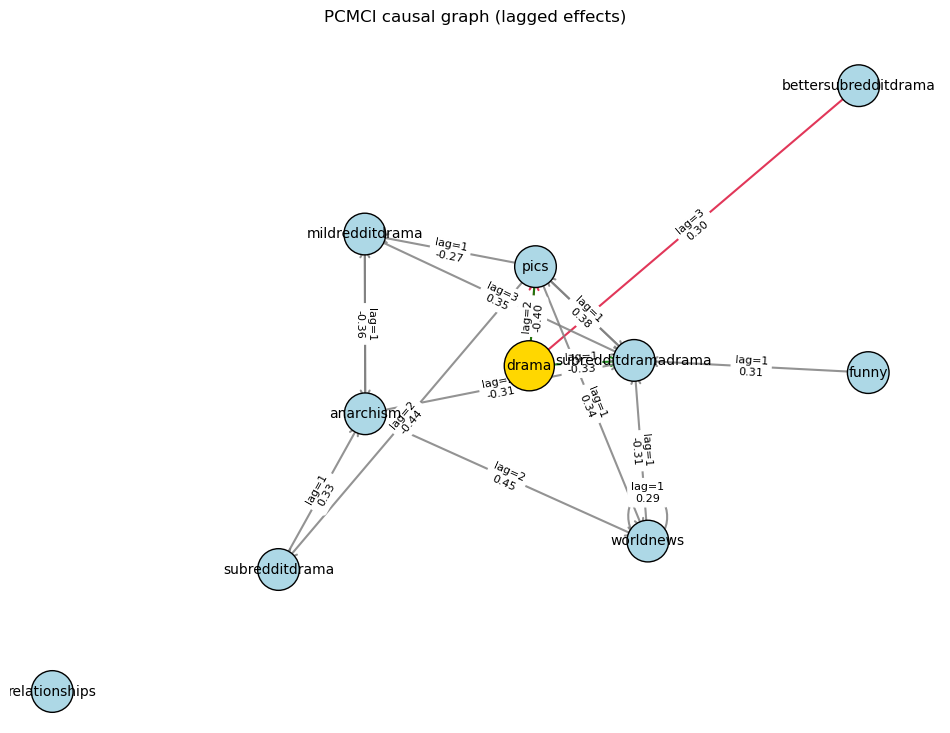

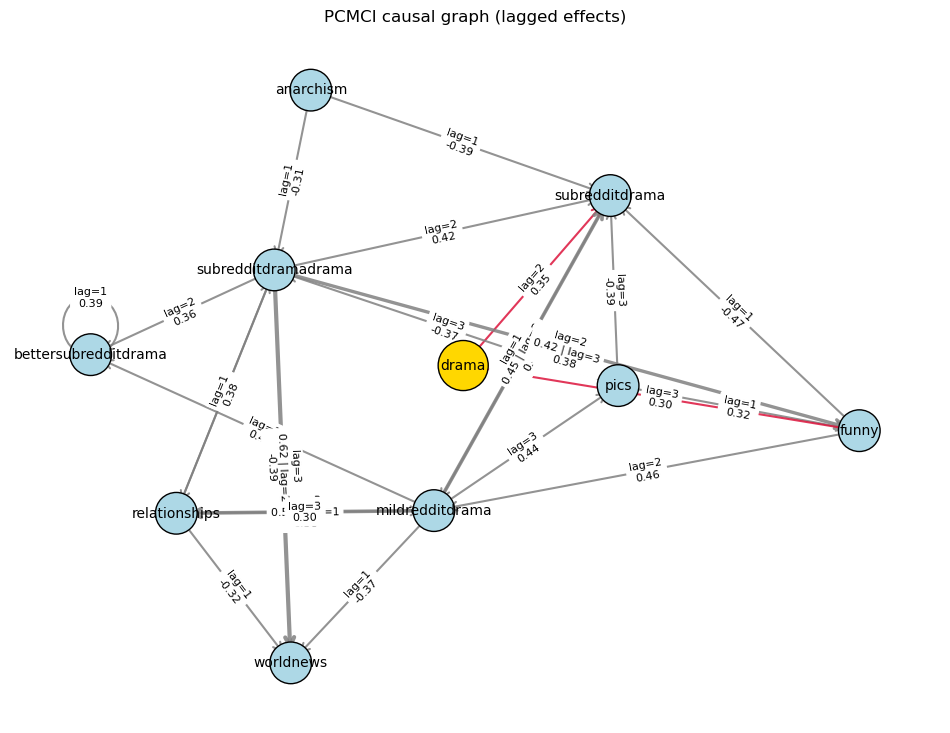

In [70]:
edges3, edges_neg3, finer_focused_subreddits3 = run_pcmci_analysis(daily_neg_interaction_df3, focused_subreddits3, sr_interaction_count_df3, interactions_df, case_study_id=3)

**CS3:**

In [71]:
plot_pcmci_interactive_html(edges1, finer_focused_subreddits1, case_study_id_py=0, output_html=f"Results_html/CS1/CS1_7_PCMCI.html")
plot_pcmci_interactive_html(edges_neg1, finer_focused_subreddits1, case_study_id_py=0, output_html=f"Results_html/CS1/CS1_8_PCMCI_negative.html")

plot_pcmci_interactive_html(edges2, finer_focused_subreddits2, case_study_id_py=1, output_html=f"Results_html/CS2/CS2_7_PCMCI.html")
plot_pcmci_interactive_html(edges_neg2, finer_focused_subreddits2, case_study_id_py=1, output_html=f"Results_html/CS2/CS2_8_PCMCI_negative.html")

plot_pcmci_interactive_html(edges3, finer_focused_subreddits3, case_study_id_py=2, output_html=f"Results_html/CS3/CS3_7_PCMCI.html")
plot_pcmci_interactive_html(edges_neg3, finer_focused_subreddits3, case_study_id_py=2, output_html=f"Results_html/CS3/CS3_8_PCMCI_negative.html")